# Предсказание отказов пневматической системы грузовиков Scania

**Датасет:** [APS Failure at Scania Trucks на Kaggle](https://www.kaggle.com/uciml/aps-failure-at-scania-trucks-data-set)  
**Тип задачи:** бинарная классификация  
**Целевая переменная:** `class`


## 0. Постановка задачи

Данные собраны при эксплуатации тяжёлых грузовиков Scania. Пневматическая система **APS (Air Pressure System)** производит сжатый воздух, который используется, в частности, в тормозной системе. По измерениям датчиков и счётчиков нужно определить, относится ли наблюдение к отказу компонента APS.

Это задача **бинарной классификации**:

- `class = neg` (далее класс `0`) — неисправность относится к компоненту, не связанному с APS;
- `class = pos` (далее класс `1`) — зафиксирован отказ компонента APS.

Всего в исходной обучающей выборке 60 000 объектов: 59 000 класса `neg` и 1 000 класса `pos`. Есть 170 входных признаков с обезличенными названиями (`aa_000`, `ab_000`, …); это числовые измерения и счётчики, в том числе бины гистограмм. Значение `na` обозначает пропуск.

**Почему задача практически важна:** пропущенный отказ может привести к поломке, а лишняя проверка исправного грузовика тоже стоит денег. Поэтому мало оценить общую долю правильных ответов: обязательно посмотрим, сколько настоящих отказов обнаруживает модель.

Источник и описание: [UCI Machine Learning Repository — APS Failure at Scania Trucks](https://archive.ics.uci.edu/dataset/421/aps%2Bfailure%2Bat%2Bscania%2Btrucks).

## 1. Чтение данных


In [53]:
import io
import os
import zipfile

# Avoid CPU-count probing in restricted Windows environments.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)

# Поиск входного файла данных.
candidates = [
    Path('aps_failure_training_set.csv'),
    Path('aps_failure_training_set.csv.zip'),
    Path('/mnt/data/aps_failure_training_set.csv'),
    Path('/mnt/data/aps_failure_training_set.csv.zip'),
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        'Не найден файл aps_failure_training_set.csv или aps_failure_training_set.csv.zip.'
    )


def read_aps_table(path):
    """Читает CSV/ZIP и автоматически пропускает служебные строки до заголовка class,..."""
    path = Path(path)
    if path.suffix.lower() == '.zip':
        with zipfile.ZipFile(path) as zf:
            csv_names = [name for name in zf.namelist() if name.lower().endswith('.csv')]
            if not csv_names:
                raise ValueError('В ZIP-архиве не найден CSV-файл.')
            # Предпочитаем обучающий файл, если в архиве несколько CSV.
            member = next((name for name in csv_names if 'training' in name.lower()), csv_names[0])
            raw = zf.read(member)
    else:
        raw = path.read_bytes()

    lines = raw.splitlines()
    header_line = None
    for i, line in enumerate(lines[:100]):
        text = line.decode('utf-8-sig', errors='replace').strip().lower()
        if text.startswith('class,'):
            header_line = i
            break
    if header_line is None:
        raise ValueError('Не удалось найти строку заголовка, начинающуюся с "class,".')

    return pd.read_csv(
        io.BytesIO(raw), skiprows=header_line,
        na_values=['na', 'NA', 'NaN', ''], low_memory=False
    )


data = read_aps_table(DATA_PATH)
data.columns = data.columns.astype(str).str.strip()
if 'class' not in data.columns:
    raise ValueError('В таблице должен быть целевой столбец class.')
data['class'] = data['class'].astype(str).str.strip().str.lower()
valid_labels = {'neg', 'pos'}
unexpected_labels = sorted(set(data['class'].dropna()) - valid_labels)
if data['class'].isna().any() or unexpected_labels:
    raise ValueError(f'Unexpected or missing class labels: {unexpected_labels}')
# Never silently discard records with unexpected target labels.
data = data.copy()

print('Файл:', DATA_PATH)
print('Размер таблицы:', data.shape)
print('Количество объектов:', len(data))
print('Количество столбцов с целевым классом:', data.shape[1])

Файл: aps_failure_training_set.csv
Размер таблицы: (60000, 171)
Количество объектов: 60000
Количество столбцов с целевым классом: 171


In [54]:
data.head()

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004,ag_005,ag_006,ag_007,...,eb_000,ec_00,ed_000,ee_000,ee_001,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,37250.0,1432864.0,3664156.0,1007684.0,...,2801180.0,2445.80,2712.0,965866.0,1706908.0,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,18254.0,653294.0,1720800.0,516724.0,...,3477820.0,2211.76,2334.0,664504.0,824154.0,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,1648.0,370592.0,1883374.0,292936.0,...,1040120.0,1018.64,1020.0,262032.0,453378.0,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,318.0,2212.0,3232.0,1872.0,0.0,...,0.0,1.08,54.0,5670.0,1566.0,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,0.0,43752.0,1966618.0,1800340.0,131646.0,...,21173050.0,1116.06,1176.0,404740.0,904230.0,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


In [55]:
print('Типы столбцов:')
print(data.dtypes.value_counts())
print('\nЦелевые классы:')
print(data['class'].value_counts())

Типы столбцов:
float64    169
object       1
int64        1
Name: count, dtype: int64

Целевые классы:
class
neg    59000
pos     1000
Name: count, dtype: int64


Столбец `class` — целевая переменная. Поэтому **170 входных признаков** получим, исключив этот столбец. Числа в именах признаков обезличены; их содержимое — счётчики и измерения, а не текстовые категории.

## 2. Разбиение на обучающую и тестовую выборки

Оставим 30% объектов для тестирования. `stratify=y` сохраняет пропорцию двух классов в обеих выборках. Все решения о заполнении пропусков и преобразовании признаков далее будут обучаться только на обучающей части.

In [56]:
from sklearn.model_selection import train_test_split

y = data['class'].map({'neg': 0, 'pos': 1}).astype(int)
X = data.drop(columns='class').apply(pd.to_numeric, errors='coerce')

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

print('Обучающая выборка:', X_train_raw.shape, '| тестовая:', X_test_raw.shape)
print('Доля pos в обучении: %.3f%%' % (100 * y_train.mean()))
print('Доля pos в тесте: %.3f%%' % (100 * y_test.mean()))

Обучающая выборка: (42000, 170) | тестовая: (18000, 170)
Доля pos в обучении: 1.667%
Доля pos в тесте: 1.667%


## 3. Визуализация и основные характеристики

Сначала изучим только обучающую выборку. У признаков разные масштабы, поэтому для графиков распределений дополнительно посмотрим на `log(1 + x)`: это помогает увидеть значения небольшого размера рядом с очень большими.

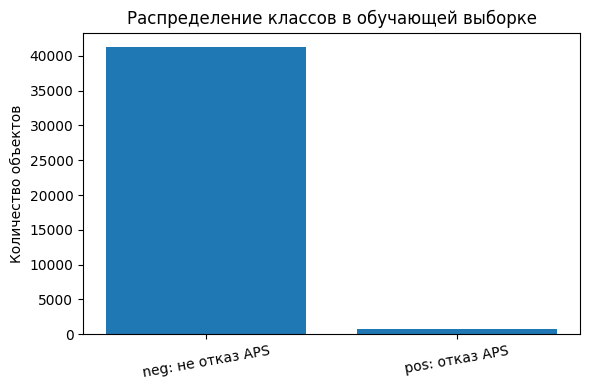

Доли классов, %:


,proportion
class,
neg: не отказ APS,98.333
pos: отказ APS,1.667


In [57]:
class_counts = y_train.value_counts().sort_index()
class_names = {0: 'neg: не отказ APS', 1: 'pos: отказ APS'}

plt.figure(figsize=(6, 4))
plt.bar([class_names[i] for i in class_counts.index], class_counts.values)
plt.ylabel('Количество объектов')
plt.title('Распределение классов в обучающей выборке')
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

print('Доли классов, %:')
display((100 * y_train.value_counts(normalize=True).sort_index()).rename(index=class_names).round(3))

In [58]:
# Основные числовые характеристики входных признаков.
display(X_train_raw.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T.head(25))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
aa_000,42000.0,5.892411e+04,1.454115e+05,0.0,4.00,10.0,838.0,30706.0,47962.5,2.158601e+05,8.250435e+05,2.746564e+06
ab_000,9612.0,7.053683e-01,3.448894e+00,0.0,0.00,0.0,0.0,0.0,0.0,4.000000e+00,8.000000e+00,2.040000e+02
ac_000,39671.0,3.593701e+08,7.978600e+08,0.0,0.00,0.0,16.0,152.0,968.0,2.130706e+09,2.130706e+09,2.130707e+09
ad_000,31583.0,2.722559e+05,4.830344e+07,0.0,0.00,2.0,24.0,126.0,430.0,1.552000e+03,4.106720e+03,8.584298e+09
ae_000,40268.0,7.515943e+00,1.874147e+02,0.0,0.00,0.0,0.0,0.0,0.0,0.000000e+00,1.200000e+02,2.105000e+04
af_000,40268.0,1.195828e+01,2.353553e+02,0.0,0.00,0.0,0.0,0.0,0.0,0.000000e+00,1.806600e+02,2.007000e+04
ag_000,41549.0,2.849434e+02,2.430915e+04,0.0,0.00,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,3.376892e+06
ag_001,41549.0,1.134680e+03,3.956918e+04,0.0,0.00,0.0,0.0,0.0,0.0,0.000000e+00,4.184000e+02,4.109372e+06
ag_002,41549.0,9.030357e+03,1.631302e+05,0.0,0.00,0.0,0.0,0.0,0.0,1.280000e+02,9.775648e+04,1.055286e+07
ag_003,41549.0,9.011918e+04,7.905458e+05,0.0,0.00,0.0,0.0,0.0,0.0,1.300880e+05,2.313470e+06,6.340207e+07


**Как интерпретировать характеристики.** Среднее и стандартное отклонение показывают уровень и разброс значений, а медиана и квантили помогают увидеть асимметрию распределений. Для датасета датчиков характерны сильно различающиеся масштабы и правые хвосты. Обезличенные имена не позволяют надёжно сопоставить каждый столбец конкретному физическому датчику, поэтому не следует приписывать `aa_000` или другим признакам не подтверждённый смысл.

In [59]:
# Сводка по пропускам: число и доля пропусков в каждом столбце.
missing_table = pd.DataFrame({
    'пропусков': X_train_raw.isna().sum(),
    'пропусков, %': 100 * X_train_raw.isna().mean()
}).sort_values('пропусков, %', ascending=False)

display(missing_table.head(20).round(2))
print('Всего пропущенных значений: %d' % X_train_raw.isna().sum().sum())
print('Доля пропусков среди всех ячеек X: %.3f%%' % (100 * X_train_raw.isna().sum().sum() / X_train_raw.size))

,пропусков,"пропусков, %"
br_000,34493,82.13
bq_000,34134,81.27
bp_000,33437,79.61
bo_000,32491,77.36
ab_000,32388,77.11
cr_000,32388,77.11
bn_000,30873,73.51
bm_000,27750,66.07
bl_000,19103,45.48
bk_000,16145,38.44


Всего пропущенных значений: 593230
Доля пропусков среди всех ячеек X: 8.309%


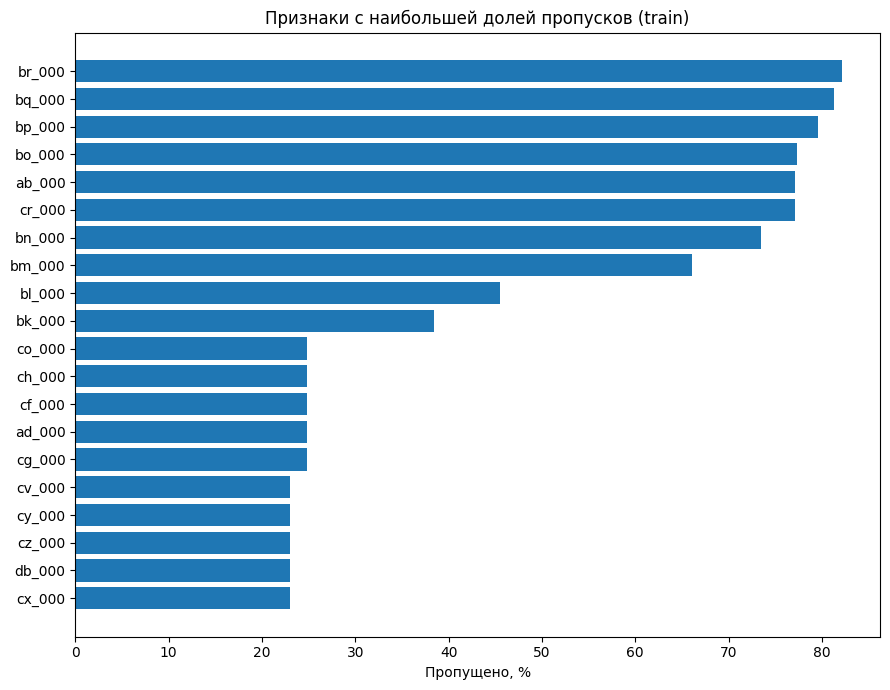

In [60]:
top_missing = missing_table.head(20).sort_values('пропусков, %')
plt.figure(figsize=(9, 7))
plt.barh(top_missing.index, top_missing['пропусков, %'])
plt.xlabel('Пропущено, %')
plt.title('Признаки с наибольшей долей пропусков (train)')
plt.tight_layout()
plt.show()

Признаки для иллюстрации распределений: ['eb_000', 'ac_000', 'ay_006', 'ag_007']


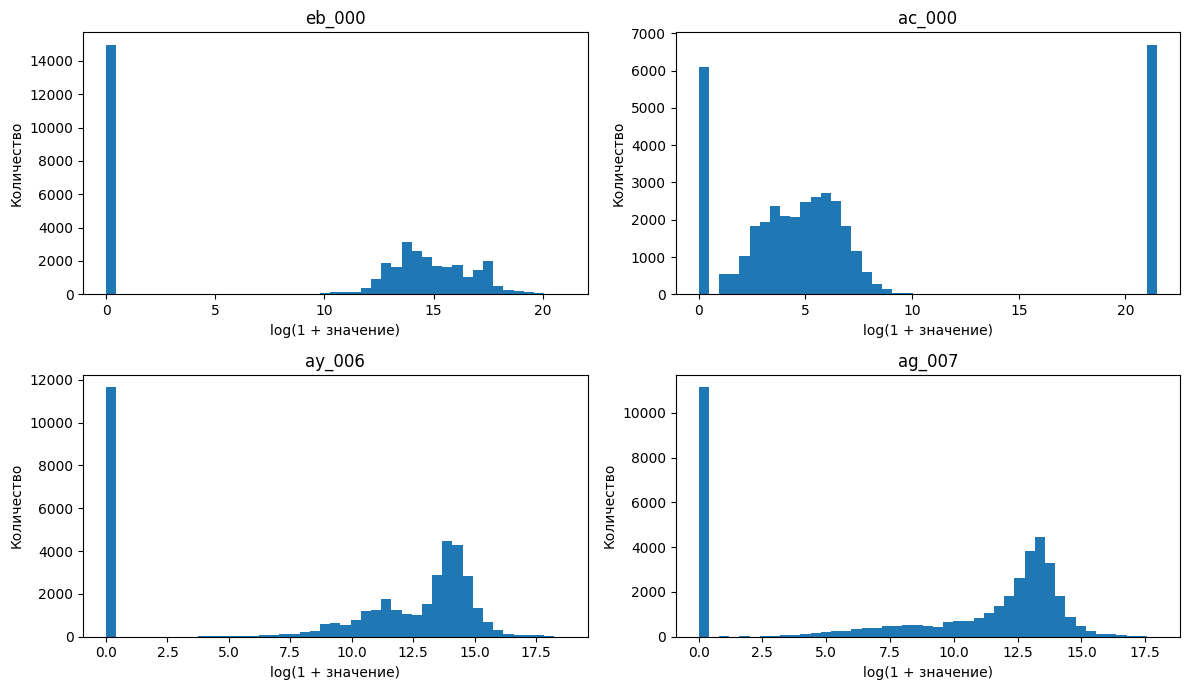

In [61]:
# Выберем несколько наиболее вариативных признаков после временного заполнения медианой.
# log1p нужен только для визуализации распределений; это ещё не подготовленные для модели данные.
eda_medians = X_train_raw.median()
X_eda_filled = X_train_raw.fillna(eda_medians).fillna(0)
X_eda_log = np.log1p(X_eda_filled.clip(lower=0))
plot_features = X_eda_log.var().sort_values(ascending=False).head(4).index.tolist()
print('Признаки для иллюстрации распределений:', plot_features)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.ravel(), plot_features):
    values = np.log1p(X_train_raw[col].dropna().clip(lower=0))
    ax.hist(values, bins=45)
    ax.set_title(col)
    ax.set_xlabel('log(1 + значение)')
    ax.set_ylabel('Количество')
plt.tight_layout()
plt.show()

У гистограмм на логарифмической шкале виден диапазон типичных значений и длинный хвост крупных измерений. Это одна из причин, почему перед k-NN нельзя использовать исходные признаки напрямую: евклидово расстояние в таком случае может определяться несколькими крупномасштабными столбцами.

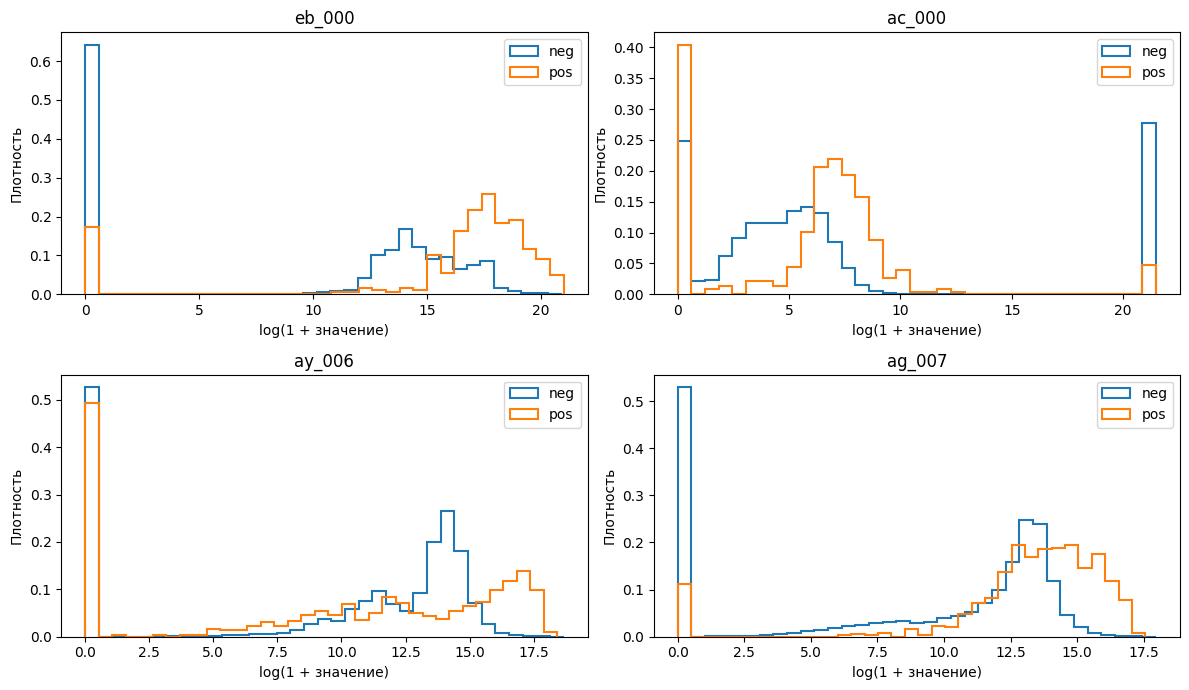

In [62]:
# Сравним распределения выбранных признаков у двух классов.
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.ravel(), plot_features):
    for cls, label in [(0, 'neg'), (1, 'pos')]:
        values = X_train_raw.loc[y_train == cls, col].dropna().clip(lower=0)
        ax.hist(np.log1p(values), bins=35, density=True, histtype='step', linewidth=1.5, label=label)
    ax.set_title(col)
    ax.set_xlabel('log(1 + значение)')
    ax.set_ylabel('Плотность')
    ax.legend()
plt.tight_layout()
plt.show()

### Корреляционная матрица

Матрица корреляций помогает найти линейно связанные признаки. Чтобы единичные экстремальные значения меньше влияли на визуализацию, для этого графика используем логарифмированные признаки с заполненными медианами. Для читаемости показываем 20 признаков с наибольшей дисперсией после такого преобразования.

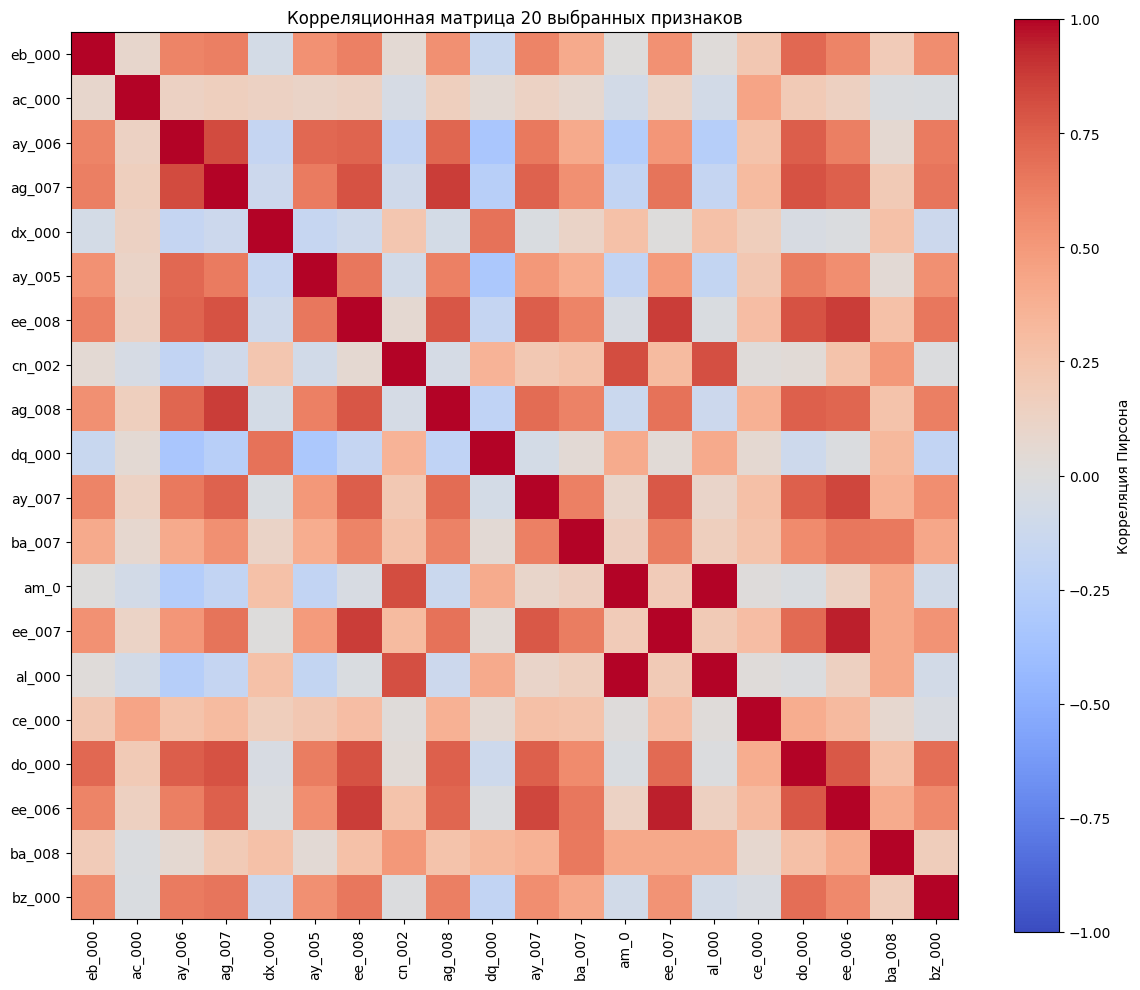

In [63]:
corr_features = X_eda_log.var().sort_values(ascending=False).head(20).index.tolist()
corr_matrix = X_eda_log[corr_features].corr()

fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(corr_matrix, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr_features)))
ax.set_yticks(range(len(corr_features)))
ax.set_xticklabels(corr_features, rotation=90)
ax.set_yticklabels(corr_features)
ax.set_title('Корреляционная матрица 20 выбранных признаков')
fig.colorbar(image, ax=ax, label='Корреляция Пирсона')
plt.tight_layout()
plt.show()

In [64]:
# Найдём пары с абсолютной корреляцией больше 0.95 среди показанных признаков.
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = (
    upper.stack().rename('корреляция').reset_index()
    .rename(columns={'level_0': 'признак 1', 'level_1': 'признак 2'})
)
high_corr_pairs = high_corr_pairs[high_corr_pairs['корреляция'].abs() > 0.95]
display(high_corr_pairs.sort_values('корреляция', key=lambda s: s.abs(), ascending=False))
print('Пар с |корреляцией| > 0.95:', len(high_corr_pairs))

,признак 1,признак 2,корреляция
163,am_0,al_000,0.993404


Пар с |корреляцией| > 0.95: 1


**Интерпретация корреляций.** Сильная корреляция указывает, что признаки могут нести похожую информацию. Для k-NN это важно, поскольку дублирующаяся информация способна непропорционально увеличить вес одной группы измерений при расчёте расстояний. В этой работе коррелированные признаки не удаляются: корреляция сама по себе не доказывает, что признак бесполезен, а сравнение моделей после отбора признаков потребовало бы отдельного эксперимента.


## 4. Выбросы

Применим правило межквартильного размаха (IQR): значение считается выбросом, если оно ниже `Q1 − 1.5·IQR` или выше `Q3 + 1.5·IQR`. Расчёт выполняется по обучающей выборке, без целевого столбца. В этом наборе у некоторых редких счётчиков межквартильный размах может быть равен нулю, поэтому правило иногда помечает редкие ненулевые показания как выбросы.

In [65]:
q1 = X_train_raw.quantile(0.25)
q3 = X_train_raw.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outlier_mask = (X_train_raw.lt(lower, axis='columns') | X_train_raw.gt(upper, axis='columns'))
outlier_mask = outlier_mask & X_train_raw.notna()
valid_values = X_train_raw.notna().sum().sum()
outlier_values = int(outlier_mask.sum().sum())
outlier_value_pct = 100 * outlier_values / valid_values if valid_values else np.nan
rows_with_outlier_pct = 100 * outlier_mask.any(axis=1).mean()
zero_iqr_count = int((iqr == 0).sum())

print('Доля значений за границами IQR среди непустых значений: %.2f%%' % outlier_value_pct)
print('Строк хотя бы с одним таким значением: %.2f%%' % rows_with_outlier_pct)
print('Признаков с IQR = 0:', zero_iqr_count, 'из', X_train_raw.shape[1])

Доля значений за границами IQR среди непустых значений: 9.24%
Строк хотя бы с одним таким значением: 94.19%
Признаков с IQR = 0: 46 из 170


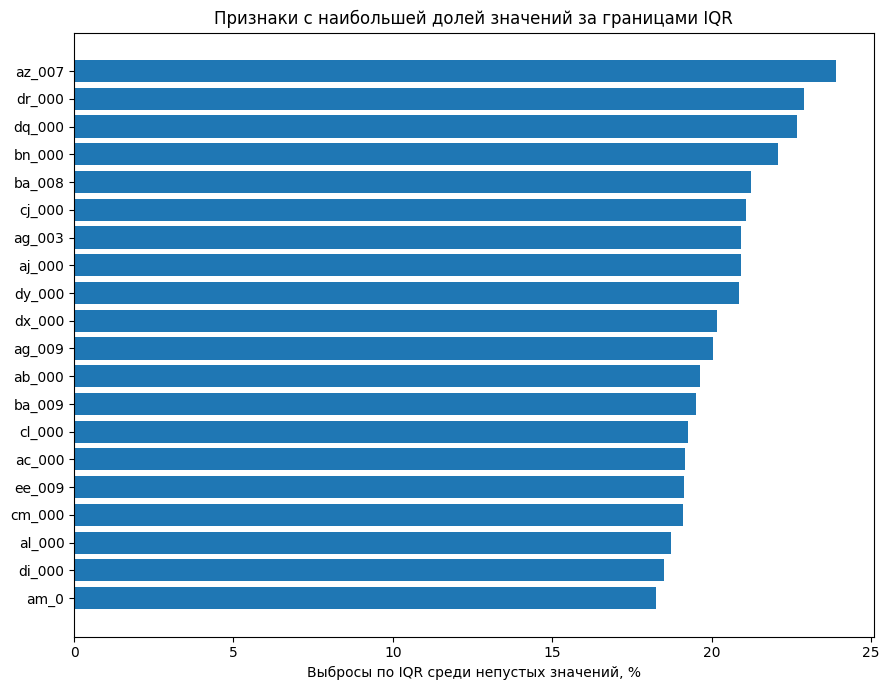

In [66]:
outlier_rate_by_feature = (100 * outlier_mask.sum() / X_train_raw.notna().sum()).fillna(0)
outlier_rate_by_feature = outlier_rate_by_feature.sort_values(ascending=False).head(20).sort_values()
plt.figure(figsize=(9, 7))
plt.barh(outlier_rate_by_feature.index, outlier_rate_by_feature.values)
plt.xlabel('Выбросы по IQR среди непустых значений, %')
plt.title('Признаки с наибольшей долей значений за границами IQR')
plt.tight_layout()
plt.show()

**Что делаем с выбросами.** Не будем автоматически удалять все строки с хотя бы одним выбросом: в датасете очень много признаков, поэтому такой подход способен удалить значительную часть наблюдений, в том числе редкие реальные отказы класса `pos`. Вместо этого при подготовке k-NN используем `log1p` для уменьшения влияния длинных правых хвостов и `RobustScaler`, масштабирование которого опирается на медиану и межквартильный размах. Деревья решений в дополнительном эксперименте вообще не требуют стандартизации признаков.

## 5. Обработка пропущенных значений

Пропуски обозначены `na` и при чтении преобразованы в `NaN`. Для каждого признака, у которого **более 70%** значений отсутствует в обучающей выборке, исключим столбец из обеих выборок. Порог и список столбцов определяются только по train — тест не используется для настройки предобработки. Остальные пропуски будем заполнять медианой внутри конвейера модели.

In [67]:
missing_fraction_train = X_train_raw.isna().mean()
columns_to_drop = missing_fraction_train[missing_fraction_train > 0.70].index.tolist()

X_train_model = X_train_raw.drop(columns=columns_to_drop).copy()
X_test_model = X_test_raw.drop(columns=columns_to_drop).copy()

print('Исключено признаков с >70% пропусков:', len(columns_to_drop))
print('Исключённые признаки:', columns_to_drop)
print('Число входных признаков после отбора:', X_train_model.shape[1])
print('Пропусков в train до заполнения:', int(X_train_model.isna().sum().sum()))

Исключено признаков с >70% пропусков: 7
Исключённые признаки: ['ab_000', 'bn_000', 'bo_000', 'bp_000', 'bq_000', 'br_000', 'cr_000']
Число входных признаков после отбора: 163
Пропусков в train до заполнения: 363026


Порог 70% — практический компромисс, а не универсальное правило. Пропущенность сама по себе может нести информацию, поэтому этот шаг стоит рассматривать как выбранную стратегию предобработки. Медианы вычисляются конвейером только при обучении на соответствующей обучающей части или фолде кросс-валидации.

## 6. Категориальные признаки

Входные измерения в данном датасете числовые. Единственный категориальный столбец — `class`, он является **целевой переменной**, а не входным признаком. Для обучения преобразуем его в `neg → 0` и `pos → 1`. Поэтому one-hot-кодирование входных категориальных признаков не требуется.

In [68]:
non_numeric_columns = X_train_model.select_dtypes(exclude=[np.number]).columns.tolist()
print('Нечисловые входные признаки после чтения:', non_numeric_columns)
print('Классы целевой переменной:', sorted(data['class'].unique()))
print('Метка pos = 1, neg = 0')

Нечисловые входные признаки после чтения: []
Классы целевой переменной: ['neg', 'pos']
Метка pos = 1, neg = 0


## 7. Нормализация

Для **k-NN нормализация нужна**, потому что метод сравнивает объекты по расстоянию. Сделаем последовательно:

1. заполнение пропусков медианой;
2. логарифмическое преобразование `log(1 + x)`, уменьшающее влияние длинных правых хвостов счётчиков;
3. `RobustScaler`, центрирующий по медиане и использующий межквартильный размах.

Все преобразования объединены в `Pipeline`, поэтому параметры считаются только на данных, на которых модель обучается. Это предотвращает утечку информации из тестовой выборки.

## 8. Классификатор ближайших соседей (k-NN)

Класс `pos` встречается редко. Если обучить k-NN на исходном соотношении классов, в окрестности объекта часто будет подавляющее большинство `neg`. Для отдельного эксперимента оставим все положительные примеры в обучении и случайно выберем **до четырёх отрицательных примеров на один положительный**. Тестовую выборку не балансируем — она сохраняет естественное распределение.

Такой undersampling ускоряет подбор `k` и даёт модели возможность чаще увидеть класс отказа, но теряет часть разнообразия класса `neg`. Поэтому результат нужно оценивать на исходной тестовой выборке и сравнивать с базовой моделью.

In [69]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Все pos из обучающей части и случайная подвыборка neg.
pos_index = y_train.index[y_train == 1]
neg_index = y_train.index[y_train == 0]
n_neg_sample = min(len(neg_index), 4 * len(pos_index))
sampled_neg_index = y_train.loc[neg_index].sample(n=n_neg_sample, random_state=42).index
balanced_index = pos_index.append(sampled_neg_index).sort_values()

X_train_balanced = X_train_model.loc[balanced_index]
y_train_balanced = y_train.loc[balanced_index]

print('Исходная обучающая выборка:', len(y_train), 'объектов')
print('Подвыборка для k-NN:', len(y_train_balanced), 'объектов')
print('Распределение классов в подвыборке:')
display(y_train_balanced.value_counts().rename(index={0: 'neg', 1: 'pos'}))

knn_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scaler', RobustScaler()),
    ('knn', KNeighborsClassifier(weights='distance', n_jobs=1))
])

Исходная обучающая выборка: 42000 объектов
Подвыборка для k-NN: 3500 объектов
Распределение классов в подвыборке:


,count
class,
neg,2800
pos,700


### Подбор числа соседей `k`

Выберем `k` по 3-блочной стратифицированной кросс-валидации. Оптимизируем **balanced accuracy** — среднее полноты по классам, которое в отличие от обычной accuracy не позволяет полностью игнорировать редкий класс. Переберём несколько небольших и средних значений `k`.

In [70]:
k_values = [1, 3, 5, 7, 11, 15, 21, 31]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid = GridSearchCV(
    knn_pipeline,
    param_grid={'knn__n_neighbors': k_values},
    scoring='balanced_accuracy',
    cv=cv,
    n_jobs=1,
    return_train_score=True,
    refit=True
)
grid.fit(X_train_balanced, y_train_balanced)

print('Лучшее k:', grid.best_params_['knn__n_neighbors'])
print('Лучшая balanced accuracy на CV: %.4f' % grid.best_score_)

Лучшее k: 3
Лучшая balanced accuracy на CV: 0.9022


,k,средняя balanced accuracy,стандартное отклонение
0,1,0.8965,0.0187
1,3,0.9022,0.0128
2,5,0.8963,0.0068
3,7,0.8913,0.0117
4,11,0.8891,0.0089
5,15,0.8768,0.0051
6,21,0.8684,0.0066
7,31,0.8600,0.0108


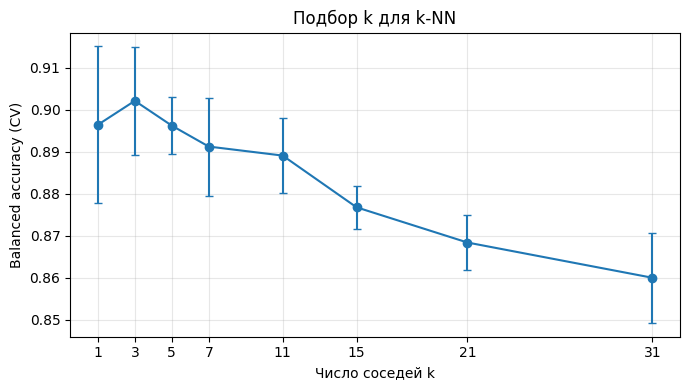

In [71]:
cv_results = pd.DataFrame({
    'k': grid.cv_results_['param_knn__n_neighbors'].astype(int),
    'средняя balanced accuracy': grid.cv_results_['mean_test_score'],
    'стандартное отклонение': grid.cv_results_['std_test_score']
}).sort_values('k')
display(cv_results.round(4))

plt.figure(figsize=(7, 4))
plt.errorbar(cv_results['k'], cv_results['средняя balanced accuracy'],
             yerr=cv_results['стандартное отклонение'], marker='o', capsize=3)
plt.xlabel('Число соседей k')
plt.ylabel('Balanced accuracy (CV)')
plt.title('Подбор k для k-NN')
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Ошибки на обучающей и тестовой выборках

Для k-NN метрики на обучении рассчитаны на той же undersampling-подвыборке, на которой модель обучалась; поэтому ошибка там оптимистична и не является оценкой качества на новых объектах. Для Random Forest показаны метрики на полной обучающей выборке, также на объектах обучения. Сравнивать качество моделей следует по общей тестовой выборке с естественным распределением классов.

In [72]:
best_knn = grid.best_estimator_
y_train_knn_pred = best_knn.predict(X_train_balanced)
y_test_knn_pred = best_knn.predict(X_test_model)


def metric_row(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    # UCI challenge metric: 10 per FP and 500 per FN.
    total_cost = 10 * fp + 500 * fn
    return {
        'Модель': name,
        'Ошибка (1 - accuracy)': 1 - accuracy_score(y_true, y_pred),
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced accuracy': balanced_accuracy_score(y_true, y_pred),
        'Precision для pos': precision_score(y_true, y_pred, zero_division=0),
        'Recall для pos': recall_score(y_true, y_pred, zero_division=0),
        'F1 для pos': f1_score(y_true, y_pred, zero_division=0),
        'UCI cost (10*FP + 500*FN)': total_cost,
    }

knn_train_metrics = metric_row('k-NN, train-подвыборка', y_train_balanced, y_train_knn_pred)
knn_test_metrics = metric_row('k-NN, test', y_test, y_test_knn_pred)
display(pd.DataFrame([knn_train_metrics, knn_test_metrics]).set_index('Модель').round(4))

,Ошибка (1 - accuracy),Accuracy,Balanced accuracy,Precision для pos,Recall для pos,F1 для pos,UCI cost (10*FP + 500*FN)
Модель,,,,,,,
"k-NN, train-подвыборка",0.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0
"k-NN, test",0.0277,0.9723,0.8893,0.3544,0.8033,0.4918,33890


In [73]:
print('Матрица рассогласования k-NN на обучающей подвыборке (строки — истина, столбцы — прогноз):')
print(confusion_matrix(y_train_balanced, y_train_knn_pred, labels=[0, 1]))
print('Порядок классов: [[TN, FP], [FN, TP]]')

print('\nМатрица рассогласования k-NN на исходной тестовой выборке:')
print(confusion_matrix(y_test, y_test_knn_pred, labels=[0, 1]))

print('\nОтчёт по тестовой выборке:')
print(classification_report(y_test, y_test_knn_pred, labels=[0, 1], target_names=['neg (нет отказа APS)', 'pos (отказ APS)'], zero_division=0))

Матрица рассогласования k-NN на обучающей подвыборке (строки — истина, столбцы — прогноз):
[[2800    0]
 [   0  700]]
Порядок классов: [[TN, FP], [FN, TP]]

Матрица рассогласования k-NN на исходной тестовой выборке:
[[17261   439]
 [   59   241]]

Отчёт по тестовой выборке:
                      precision    recall  f1-score   support

neg (нет отказа APS)       1.00      0.98      0.99     17700
     pos (отказ APS)       0.35      0.80      0.49       300

            accuracy                           0.97     18000
           macro avg       0.68      0.89      0.74     18000
        weighted avg       0.99      0.97      0.98     18000



В матрице рассогласования строки — истинные классы, столбцы — предсказанные. **FN** — реальные отказы APS, которые модель пропустила; **FP** — ложные тревоги. По метрике UCI ложная тревога стоит 10, а пропущенный отказ — 500, поэтому итоговая стоимость равна `10 × FP + 500 × FN`. Это делает особенно важным выявление класса `pos`. Стоимость рассчитана для каждой модели на тестовой выборке; она не использовалась для настройки по тесту.

### Базовый вариант: всегда предсказывать `neg`

При дисбалансе классов простая модель, которая никогда не прогнозирует отказ APS, может иметь accuracy около 98,3%. Это не означает, что она полезна: она пропустит все отказы. Базовую модель сравним также по стоимости ошибок UCI, где пропуск отказа значительно дороже ложной тревоги.

In [74]:
y_test_baseline = np.zeros(len(y_test), dtype=int)
baseline_metrics = metric_row('Всегда neg (test)', y_test, y_test_baseline)
display(pd.DataFrame([baseline_metrics]).set_index('Модель').round(4))
print('Матрица рассогласования базовой модели:')
print(confusion_matrix(y_test, y_test_baseline, labels=[0, 1]))

,Ошибка (1 - accuracy),Accuracy,Balanced accuracy,Precision для pos,Recall для pos,F1 для pos,UCI cost (10*FP + 500*FN)
Модель,,,,,,,
Всегда neg (test),0.0167,0.9833,0.5,0.0,0.0,0.0,150000


Матрица рассогласования базовой модели:
[[17700     0]
 [  300     0]]


Сопоставление `recall` класса `pos` у k-NN и базового алгоритма показывает, обнаруживает ли модель больше настоящих отказов, чем стратегия «всегда neg». При оценке важно учитывать компромисс: увеличение числа обнаруженных отказов может сопровождаться ростом числа ложных срабатываний.


## 10. Дополнительный классификатор: Random Forest

Сравним k-NN с случайным лесом. Случайный лес строит много деревьев решений, умеет моделировать нелинейные зависимости и не требует стандартизации признаков. Обучим его на всей исходной обучающей выборке с `class_weight='balanced_subsample'`, чтобы увеличить влияние редкого класса. Пропуски заполним медианой, найденной по train.

In [75]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('rf', RandomForestClassifier(
        n_estimators=150,
        min_samples_leaf=2,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=1
    ))
])

rf_pipeline.fit(X_train_model, y_train)
y_train_rf_pred = rf_pipeline.predict(X_train_model)
y_test_rf_pred = rf_pipeline.predict(X_test_model)

rf_train_metrics = metric_row('Random Forest, train', y_train, y_train_rf_pred)
rf_test_metrics = metric_row('Random Forest, test', y_test, y_test_rf_pred)
display(pd.DataFrame([rf_train_metrics, rf_test_metrics]).set_index('Модель').round(4))

print('Матрица рассогласования Random Forest на тесте:')
print(confusion_matrix(y_test, y_test_rf_pred, labels=[0, 1]))
print('\nОтчёт по тестовой выборке:')
print(classification_report(y_test, y_test_rf_pred, labels=[0, 1], target_names=['neg (нет отказа APS)', 'pos (отказ APS)'], zero_division=0))

,Ошибка (1 - accuracy),Accuracy,Balanced accuracy,Precision для pos,Recall для pos,F1 для pos,UCI cost (10*FP + 500*FN)
Модель,,,,,,,
"Random Forest, train",0.0000,1.0000,1.0000,0.9986,1.0000,0.9993,10
"Random Forest, test",0.0075,0.9925,0.8373,0.8423,0.6767,0.7505,48880


Матрица рассогласования Random Forest на тесте:
[[17662    38]
 [   97   203]]

Отчёт по тестовой выборке:
                      precision    recall  f1-score   support

neg (нет отказа APS)       0.99      1.00      1.00     17700
     pos (отказ APS)       0.84      0.68      0.75       300

            accuracy                           0.99     18000
           macro avg       0.92      0.84      0.87     18000
        weighted avg       0.99      0.99      0.99     18000



,Ошибка (1 - accuracy),Accuracy,Balanced accuracy,Precision для pos,Recall для pos,F1 для pos,UCI cost (10*FP + 500*FN)
Модель,,,,,,,
Всегда neg,0.0167,0.9833,0.5000,0.0000,0.0000,0.0000,150000
k-NN (подобранный k),0.0277,0.9723,0.8893,0.3544,0.8033,0.4918,33890
Random Forest,0.0075,0.9925,0.8373,0.8423,0.6767,0.7505,48880


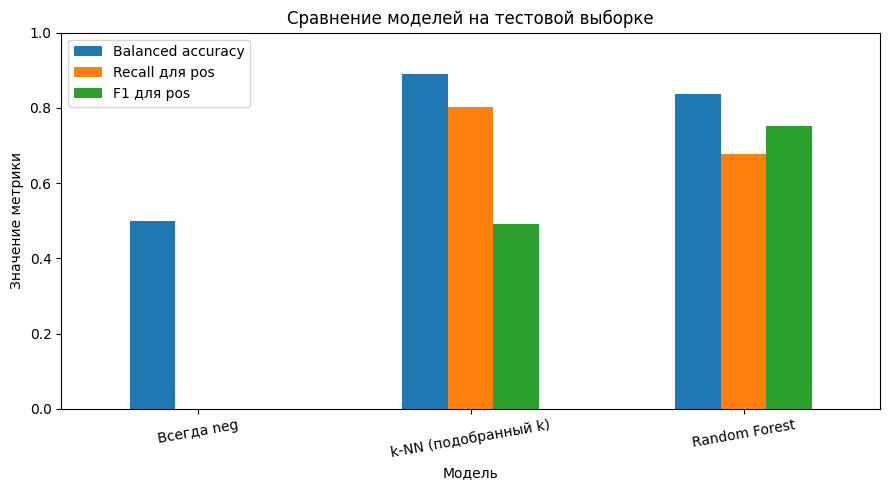

In [76]:
# Сопоставим тестовые результаты. Accuracy нужно рассматривать вместе с метриками редкого класса.
comparison = pd.DataFrame([
    metric_row('Всегда neg', y_test, y_test_baseline),
    metric_row('k-NN (подобранный k)', y_test, y_test_knn_pred),
    metric_row('Random Forest', y_test, y_test_rf_pred),
]).set_index('Модель')

display(comparison.round(4))

comparison[['Balanced accuracy', 'Recall для pos', 'F1 для pos']].plot(kind='bar', figsize=(9, 5))
plt.ylabel('Значение метрики')
plt.title('Сравнение моделей на тестовой выборке')
plt.xticks(rotation=10)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### Значимость признаков случайного леса

Случайный лес позволяет оценить важность входных признаков. Названия обезличены, поэтому список покажет, какие столбцы модель использует сильнее, но не даст сам по себе физического объяснения.

,важность
ci_000,0.065879
aa_000,0.056471
bb_000,0.052531
bj_000,0.047782
ck_000,0.047628
dn_000,0.047391
ap_000,0.047279
bt_000,0.042418
aq_000,0.037044
bv_000,0.035686


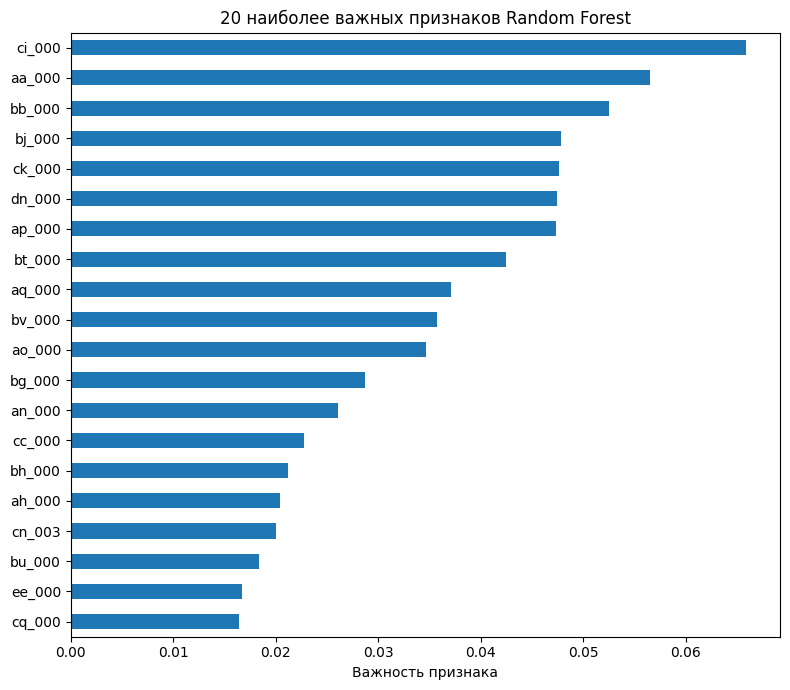

In [77]:
rf_importance = pd.Series(
    rf_pipeline.named_steps['rf'].feature_importances_,
    index=X_train_model.columns
).sort_values(ascending=False)

display(rf_importance.head(20).rename('важность').to_frame())
rf_importance.head(20).sort_values().plot(kind='barh', figsize=(8, 7))
plt.xlabel('Важность признака')
plt.title('20 наиболее важных признаков Random Forest')
plt.tight_layout()
plt.show()

## 11. Несбалансированность классов

Дисбаланс выражен сильно: положительных примеров около 1,7%. В этой работе применены два разных подхода для сравнения:

- для k-NN уменьшили число объектов большинства в обучении, сохранив все положительные примеры;
- для Random Forest использовали `class_weight='balanced_subsample'`.

Сравниваем модели на **одной и той же исходной тестовой выборке**, где классы не балансировались. Это позволяет увидеть компромисс между пропущенными отказами (FN) и ложными сигналами (FP), а также сравнить их стоимость по метрике UCI. Подбор `k` по balanced accuracy отражает качество для обоих классов; стоимость здесь приводится как дополнительная прикладная оценка.

## 12. Коррелированные признаки

Корреляционная матрица позволяет выявить пары потенциально дублирующих признаков. В основном эксперименте они сохранены: удаление признаков изменяет пространство расстояний для k-NN, но высокая корреляция не гарантирует, что удаление улучшит качество. Поэтому корреляционный анализ используется как диагностический этап, а модели сравниваются на одинаковом наборе входных признаков.


## 13. Общие выводы

In [78]:
print('1. Данные:', len(data), 'объектов и', X.shape[1], 'входных признаков до предобработки.')
print('2. Доля класса pos в данных: %.3f%%.' % (100 * y.mean()))
print('3. Пропущено %.3f%% ячеек входных признаков в train.' %
      (100 * X_train_raw.isna().sum().sum() / X_train_raw.size))
print('4. По правилу IQR выбросами помечено %.2f%% непустых значений train; строк хотя бы с одним таким значением — %.2f%%.' %
      (outlier_value_pct, rows_with_outlier_pct))
print('5. Для k-NN выбран k = %d; лучшая balanced accuracy на CV = %.4f.' %
      (grid.best_params_['knn__n_neighbors'], grid.best_score_))
print('6. На тесте: k-NN recall(pos) = %.4f, Random Forest recall(pos) = %.4f.' %
      (recall_score(y_test, y_test_knn_pred, zero_division=0), recall_score(y_test, y_test_rf_pred, zero_division=0)))
print('7. Базовая модель всегда neg имеет recall(pos) = %.4f.' %
      recall_score(y_test, y_test_baseline, zero_division=0))
print('8. UCI cost on test (10*FP + 500*FN): k-NN = %d, Random Forest = %d, baseline = %d.' %
      (knn_test_metrics['UCI cost (10*FP + 500*FN)'],
       rf_test_metrics['UCI cost (10*FP + 500*FN)'],
       baseline_metrics['UCI cost (10*FP + 500*FN)']))
print('\nИнтерпретация качества основана на тестовых метриках и матрице ошибок, а не только на accuracy.')

1. Данные: 60000 объектов и 170 входных признаков до предобработки.
2. Доля класса pos в данных: 1.667%.
3. Пропущено 8.309% ячеек входных признаков в train.
4. По правилу IQR выбросами помечено 9.24% непустых значений train; строк хотя бы с одним таким значением — 94.19%.
5. Для k-NN выбран k = 3; лучшая balanced accuracy на CV = 0.9022.
6. На тесте: k-NN recall(pos) = 0.8033, Random Forest recall(pos) = 0.6767.
7. Базовая модель всегда neg имеет recall(pos) = 0.0000.
8. UCI cost on test (10*FP + 500*FN): k-NN = 33890, Random Forest = 48880, baseline = 150000.

Интерпретация качества основана на тестовых метриках и матрице ошибок, а не только на accuracy.


### Итоговая интерпретация

1. Решалась задача бинарной классификации: отличить отказ компонента APS от неисправностей других компонентов.
2. Входные признаки числовые, имеют разные масштабы и длинные хвосты распределений; присутствуют пропуски и сильный дисбаланс классов.
3. Пропуски заполнены медианами внутри конвейеров моделей. Признаки с долей пропусков более 70% исключены на основании обучающей выборки. Для k-NN применены `log1p` и `RobustScaler`.
4. Выбросы выявлены правилом IQR, но автоматически не удалялись: экстремальные значения могут отражать реальные режимы работы оборудования, а удаление строк с выбросами может непропорционально затронуть редкий положительный класс.
5. Число соседей `k` подобрано стратифицированной кросс-валидацией по balanced accuracy. k-NN сопоставлен с Random Forest и базовой моделью, всегда предсказывающей `neg`.
6. Из-за дисбаланса классов accuracy недостаточно для оценки модели. Рассматриваются recall и F1 класса `pos`, матрицы ошибок и стоимость `10 × FP + 500 × FN` по метрике UCI. `k` выбирается по balanced accuracy на кросс-валидации, а тестовая выборка используется только для итоговой оценки.
7. На тесте recall класса `pos` составил 0,80 у k-NN и 0,68 у Random Forest; у Random Forest выше precision (0,84 против 0,35) и F1 (0,75 против 0,49). Стоимость ошибок равна 33 890 для k-NN, 48 880 для Random Forest и 150 000 для базовой модели. По метрике стоимости на этом разбиении выигрывает k-NN; выбор в рабочей системе зависит от того, насколько важны полнота обнаружения и число ложных тревог.